# Стадия 3. Модель предсказания исхода

**Источник данных:** `train_model.parquet` (стадия 1); первичный датасет — Kaggle S3E26, первоисточник — UCI Cirrhosis.
**Предыдущие этапы:** `Stage_1_analysis.ipynb` — анализ данных и отбор 15 признаков;
`Stage_2_regression.ipynb` — проверка, почему для этой задачи не подходит оценка по числу (линейная регрессия).

**Цель стадии.** Построить корректную модель предсказания исхода пациента (`Status`: жив / перенёс трансплантацию / умер) и разобраться, как редкость класса «трансплантация» влияет на обучение и на оценку качества.

Стадия 2 показала: линейная регрессия здесь неприменима, потому что ответ — категория, а не число. Корректный линейный инструмент — **логистическая регрессия**: она предсказывает не значение, а вероятность каждого исхода.

**В чём главная трудность.** Класс `CL` (трансплантация) — 275 строк из 7 905, то есть 3.5 %. В контрольной выборке таких пациентов всего 69. Модель, которая никогда не предсказывает `CL`, всё равно получает высокую долю верных ответов. Это и есть проблема дисбаланса классов: общая точность скрывает провал на редком классе.

**Что берём в работу.** Ту же матрицу из **15 признаков** и то же разбиение 75/25 со стратификацией и `random_state=42`, что и в стадии 2. Отличие: цель не кодируется порядковой шкалой, логистическая регрессия работает с классами как с метками.

## **1. Импорты и настройки**

In [1]:
# Сторонние библиотеки
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             classification_report, f1_score, log_loss,
                             precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

## **2. Загрузка данных**

Данные берутся из `data/processed/train_model.parquet` — итогового набора стадии 1: 15 признаков и цель `Status`, 7 905 строк после очистки. Повторная очистка и отбор не требуются: все решения приняты и обоснованы на стадии 1.

In [2]:
# Корень проекта: папка с data/, найденная вверх по дереву от текущей директории
def find_project_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(d, 'data')):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            raise FileNotFoundError('Папка data/ не найдена вверх по дереву от ' + d)
        d = parent


PROJECT_ROOT = find_project_root()
df = pd.read_parquet(os.path.join(PROJECT_ROOT, 'data', 'processed', 'train_model.parquet'))
print(f'Строк: {len(df)}, столбцов: {df.shape[1]} (15 признаков + цель)')
df.head(3)

Строк: 7905, столбцов: 16 (15 признаков + цель)


,log_Bilirubin,log_Copper,log_Alk_Phos,log_SGOT,log_Cholesterol,log_Tryglicerides,Albumin,Platelets,Prothrombin,Age_years,Stage,Edema_num,Sex_M,Hepatomegaly_Y,Spiders_Y,Status
0,1.193922,5.153292,7.379008,5.197391,5.758902,4.158883,3.35,394.0,9.7,59.0,3.0,0.0,1,0,0,D
1,0.641854,4.158883,7.273093,4.911551,5.899897,4.488636,3.54,361.0,11.0,52.7,3.0,0.0,0,0,0,C
2,1.458615,4.882802,6.937314,4.790404,5.703782,3.931826,3.55,199.0,11.7,37.6,4.0,1.0,0,1,1,D


### Целевая переменная и дисбаланс классов

`Status` — номинальная цель с тремя классами. В отличие от стадии Stage_2 мы **не** кодируем её
порядковой шкалой `C=0, CL=1, D=2`: логистическая регрессия работает с классами как с метками,
каждый класс получает собственный вектор весов, и ложное предположение о равных «шагах» между
исходами не возникает.

In [3]:
y = df['Status'].astype(str)

balance = pd.DataFrame({
    'строк': y.value_counts(),
    'доля': y.value_counts(normalize=True).round(4),
})
balance.index.name = 'класс'
print('Целевая переменная Status:')
display(balance)

print('Классы по убыванию численности:', list(y.value_counts().index))
print(f'Мажоритарный/миноритарный: {y.value_counts().max()} строк против '
      f'{y.value_counts().min()} (в {y.value_counts().max() / y.value_counts().min():.1f} раза меньше)')


Целевая переменная Status:


,строк,доля
класс,,
C,4965,0.6281
D,2665,0.3371
CL,275,0.0348


Классы по убыванию численности: ['C', 'D', 'CL']
Мажоритарный/миноритарный: 4965 строк против 275 (в 18.1 раза меньше)


> **Что видим:** миноритарный класс `CL` — 275 строк (3.5 %). Это тот случай, когда доля
> верных ответов теряет смысл: модель, которая никогда не предсказывает `CL`, получает
> «бесплатные» 62.8 % по классу `C` и 33.7 % по `D`. Ниже это станет главной сюжетной
> линией стадии.

## **3. Подготовка признаков**

Матрица признаков — это все столбцы файла, кроме цели. Дополнительное кодирование не нужно: бинарные признаки уже приведены к 0/1 на стадии 1, порядковая шкала отёков — к числам 0 / 0.5 / 1, скошенные лабораторные показатели — к логарифмам.

Напоминание, почему в наборе ровно 15 столбцов (обоснование — блоки 2.5, 3.10, 3.12, 3.13 стадии 1):

| Причина исключения | Столбцы |
|---|---|
| Дублируют выбранный вариант того же факта | `Bilirubin`, `Copper`, `Alk_Phos`, `SGOT`, `Cholesterol`, `Tryglicerides`, `Age`, `Edema`, `is_severe` |
| Дублируют отёки (корреляция 0.635) | `Ascites` |
| Известен только после наступления исхода | `N_Days` (период наблюдения) |
| Не связан с исходом / технический | `Drug`, `id` |
| Прямая утечка цели | `is_dead` |

Последний пункт заслуживает отдельного упоминания: `is_dead` — это `Status == 'D'`, то есть половина ответа на вопрос задачи. Модель с таким «признаком» показывала бы почти идеальные метрики, предсказывая то, что уже известно.

In [4]:
X = df.drop(columns=['Status']).astype(float)
y = df['Status'].astype(str)

print(f'Матрица признаков: {X.shape[0]} строк x {X.shape[1]} столбцов')
print('Столбцы:', list(X.columns))
print('\nПропусков:', int(X.isna().sum().sum()))

Матрица признаков: 7905 строк x 15 столбцов
Столбцы: ['log_Bilirubin', 'log_Copper', 'log_Alk_Phos', 'log_SGOT', 'log_Cholesterol', 'log_Tryglicerides', 'Albumin', 'Platelets', 'Prothrombin', 'Age_years', 'Stage', 'Edema_num', 'Sex_M', 'Hepatomegaly_Y', 'Spiders_Y']

Пропусков: 0


## **4. Разбиение и стандартизация**

Два обязательных шага, порядок которых нельзя менять.

**Стратифицированное разбиение.** При обычном разбиении редкий класс `CL` может попасть в одну
из частей непропорционально, и оценка качества станет случайной. `stratify=y` гарантирует, что
доли классов в train и test совпадут с долями в исходной выборке.

**Стандартизация после разбиения.** `StandardScaler` обучается (`fit`) только на train и лишь
затем применяется (`transform`) к test. Если масштабировать всю выборку разом, в статистику
признаков (среднее, стандартное отклонение) просочится информация из тестовой части — это
утечка более тонкого типа (data leakage через предобработку), и она делает оценку качества
оптимистичной.

Логистической регрессии стандартизация нужна по двум причинам: регуляризация L2 штрафует
коэффициенты, и без единого масштаба штраф ложится на признаки неравномерно; а градиентные
методы сходятся по вытянутому эллипсу функций потерь медленно.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

print('Размеры выборок:', X_train.shape[0], 'train /', X_test.shape[0], 'test')
print('\nРаспределение классов (доли должны совпадать с исходными):')
cmp = pd.DataFrame({
    'train': y_train.value_counts(normalize=True),
    'test': y_test.value_counts(normalize=True),
    'всего': y.value_counts(normalize=True),
}).round(4)
cmp.index.name = 'класс'
display(cmp)

print('Абсолютные числа в test:', y_test.value_counts().to_dict())
print('=> Класс CL: всего 275 строк, из них', int((y_test == 'CL').sum()), 'в тестовой выборке')

scaler = StandardScaler()
X_tr = scaler.fit_transform(X_train)   # fit только на train
X_te = scaler.transform(X_test)        # к test — только transform
print(f'\nСтандартизованные матрицы: train {X_tr.shape}, test {X_te.shape}')

Размеры выборок: 5928 train / 1977 test

Распределение классов (доли должны совпадать с исходными):


,train,test,всего
класс,,,
C,0.6280,0.6282,0.6281
D,0.3372,0.3369,0.3371
CL,0.0348,0.0349,0.0348


Абсолютные числа в test: {'C': 1242, 'D': 666, 'CL': 69}
=> Класс CL: всего 275 строк, из них 69 в тестовой выборке

Стандартизованные матрицы: train (5928, 15), test (1977, 15)


## **5. Базовая модель: логистическая регрессия**

`LogisticRegression` решает многоклассовую задачу через **softmax**: для каждого исхода `k` считается линейная функция `z_k = w_k · x + b_k`, затем

$$P(y = k \mid x) = \frac{e^{z_k}}{\sum_{j} e^{z_j}}$$

Вероятности всех трёх исходов в сумме дают 1, а предсказание — самый вероятный исход. Это и есть ответ на вопрос стадии 2: цель остаётся категориальной, модель предсказывает распределение на трёх классах, а не число на произвольной прямой.

`max_iter=1000` — ограничение на число итераций оптимизатора: при дефолтных 100 модель на несбалансированных данных может не успеть сойтись.

Заведём функцию оценки и список результатов: к ним мы вернёмся в сводном сравнении (блок 10). Названия метрик — русские, чтобы таблица была понятна без расшифровки.

In [6]:
results = []


def evaluate(model, X_eval, y_eval, tag):
    # Считает набор метрик классификации и возвращает строку для сводной таблицы.
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)
    return {
        'вариант': tag,
        'доля верных ответов': accuracy_score(y_eval, y_pred),
        'ср. доля верных по классам': balanced_accuracy_score(y_eval, y_pred),
        'F-мера (ср. по классам)': f1_score(y_eval, y_pred, average='macro'),
        'F-мера (взвеш. по численности)': f1_score(y_eval, y_pred, average='weighted'),
        'лог-потеря': log_loss(y_eval, y_proba, labels=model.classes_),
        'полнота CL': recall_score(y_eval, y_pred, labels=['CL'], average=None)[0],
    }


base_model = LogisticRegression(max_iter=1000, random_state=42)
base_model.fit(X_tr, y_train)

y_pred_base = base_model.predict(X_te)
print('Классы модели:', list(base_model.classes_))
print('\nОтчёт по классам (базовая модель, контрольная часть):')
print(classification_report(y_test, y_pred_base, digits=3,
                            target_names=['C (жив)', 'CL (трансплантация)', 'D (умер)']))

results.append(evaluate(base_model, X_te, y_test, 'базовая'))

Классы модели: ['C', 'CL', 'D']

Отчёт по классам (базовая модель, контрольная часть):
                     precision    recall  f1-score   support

            C (жив)      0.817     0.900     0.856      1242
CL (трансплантация)      1.000     0.014     0.029        69
           D (умер)      0.746     0.680     0.712       666

           accuracy                          0.795      1977
          macro avg      0.854     0.532     0.532      1977
       weighted avg      0.799     0.795     0.779      1977



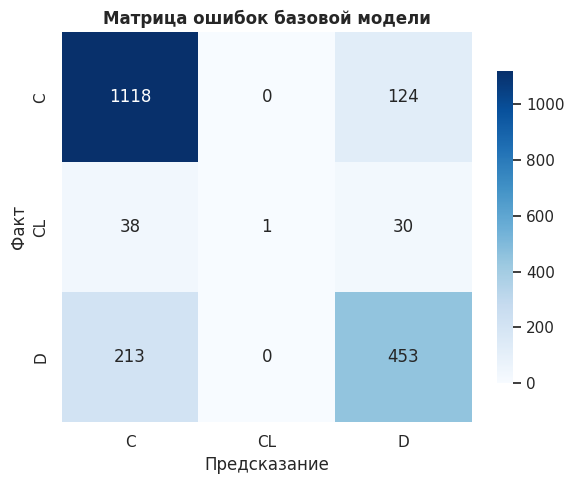

Диагональ (верно): [1118    1  453] => сумма 1572 из 1977 (79.5%)
Класс CL (вторая строка): верно найден 1 из 69


In [7]:
# Матрица ошибок: строки — фактический класс, столбцы — предсказанный
cm_base = confusion_matrix(y_test, y_pred_base, labels=base_model.classes_)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=base_model.classes_, yticklabels=base_model.classes_,
            cbar_kws={'shrink': 0.8})
ax.set_xlabel('Предсказание')
ax.set_ylabel('Факт')
ax.set_title('Матрица ошибок базовой модели', fontweight='bold')
plt.tight_layout()
plt.show()

print('Диагональ (верно):', np.diag(cm_base), '=> сумма', int(np.trace(cm_base)),
      f'из {len(y_test)} ({np.trace(cm_base) / len(y_test):.1%})')
print('Класс CL (вторая строка): верно найден', cm_base[1, 1], 'из', cm_base[1].sum())

### Вывод по базовой модели: доля верных ответов здесь обманчива

| Метрика | Значение | Как читать |
|---|---|---|
| Доля верных ответов (accuracy) | 0.795 | Выглядит хорошо, но почти ничего не говорит |
| Ср. доля верных по классам | 0.532 | Средняя полнота по классам — вдвое ниже общей доли верных ответов |
| F-мера (ср. по классам) | 0.532 | Классы равноправны: редкий класс тянет оценку вниз |
| F-мера (взвеш. по численности) | 0.779 | Взвешена по численности классов: почти повторяет общую долю верных ответов |
| Лог-потеря | 0.544 | Единственная метрика, штрафующая за уверенность в неверном ответе |
| Полнота класса CL | 0.014 | Из 69 пациентов с трансплантацией найден 1 |

Ключевая строка матрицы ошибок: `CL: 38 / 1 / 30`. Модель распределяет реальных пациентов
класса `CL` между `C` и `D`, но почти никогда не называет `CL`. При этом доля верных ответов
0.795 — выше доли мажоритарного класса. Разница между общей долей верных ответов (0.795) и средней
по классам (0.532) — прямой диагноз: качество модели сосредоточено в крупных классах.

Поэтому дальше мы сравниваем варианты по **F-мере (средней по классам)** и **полноте класса
CL**, а лог-потерю оставляем как метрику калибровки вероятностей: она проверяет, не сломали ли мы
калибровку вероятностей.

## **6. Почему период наблюдения не вошёл в модель**

Период наблюдения (`N_Days`) — сколько дней пациент состоял под наблюдением до развязки — самый обманчивый столбец датасета. На стадии 1 (блок 3.10) он был исключён из признаков по логической причине; здесь мы проверяем это решение **на модели**, чтобы вывод опирался не только на рассуждение, но и на числа.

**Напоминание сути.** Период измеряет время **до** завершения наблюдения, то есть становится известен только тогда, когда исход уже наступил. Это не причина исхода, а его часть: пациент, умерший на 400-й день, не мог наблюдаться дольше. Модель, использующая период, отвечает не на вопрос «каков прогноз пациента», а на вопрос «какой исход согласуется с такой длительностью наблюдения» — для нового пациента на приёме сегодня такой признак взять неоткуда.

**Что проверяем.** Контрольный опыт: та же модель, то же разбиение данных, но к 15 признакам добавляем период. Если бы период нёс полезную для прогноза информацию, метрики заметно выросли бы.

In [8]:
# Контрольный опыт: 15 признаков + период наблюдения
df_full = pd.read_parquet(os.path.join(PROJECT_ROOT, 'data', 'processed', 'train_clean.parquet'))
X_days = df_full[list(X.columns) + ['N_Days']].astype(float)
y_days = df_full['Status'].astype(str)

Xtr_d, Xte_d, ytr_d, yte_d = train_test_split(
    X_days, y_days, test_size=0.25, stratify=y_days, random_state=42)
sc_d = StandardScaler()
A_d = sc_d.fit_transform(Xtr_d)
B_d = sc_d.transform(Xte_d)

model_days = LogisticRegression(max_iter=1000, random_state=42)
model_days.fit(A_d, ytr_d)
results.append(evaluate(model_days, B_d, yte_d, '+ период наблюдения (контроль)'))

compare = pd.DataFrame(results[:2]).set_index('вариант').round(4)
display(compare)

delta = compare.iloc[1] - compare.iloc[0]
print('\nРазница (контроль минус базовая):')
display(delta.rename('Δ').to_frame().round(4))

print('=> Добавление периода меняет метрики на тысячные доли — это уровень шума:')
print('   доля верных ответов: +0.0016 — примерно 3 пациента из 1 977.')
print('   Логический аргумент стадии 1 подтверждается числами: линейная модель')
print('   почти не выигрывает от периода, а его использование делает модель')
print('   неприменимой к новому пациенту. Период остаётся исключённым.')

,доля верных ответов,ср. доля верных по классам,F-мера (ср. по классам),F-мера (взвеш. по численности),лог-потеря,полнота CL
вариант,,,,,,
базовая,0.7951,0.5316,0.5322,0.7787,0.5438,0.0145
+ период наблюдения (контроль),0.7967,0.5333,0.5336,0.7805,0.5400,0.0145



Разница (контроль минус базовая):


,Δ
доля верных ответов,0.0016
ср. доля верных по классам,0.0017
F-мера (ср. по классам),0.0014
F-мера (взвеш. по численности),0.0018
лог-потеря,-0.0038
полнота CL,0.0000


=> Добавление периода меняет метрики на тысячные доли — это уровень шума:
   доля верных ответов: +0.0016 — примерно 3 пациента из 1 977.
   Логический аргумент стадии 1 подтверждается числами: линейная модель
   почти не выигрывает от периода, а его использование делает модель
   неприменимой к новому пациенту. Период остаётся исключённым.


### Вывод по периоду наблюдения

Контрольный опыт показал: качество модели от добавления периода меняется на тысячные доли — в пределах статистического шума. При этом цена использования периода велика и другого рода:

- **Модель перестаёт отвечать на медицинский вопрос.** Прогноз нужен врачу сегодня, когда периода ещё нет. Модель, обученная с периодом, на новых данных просто неприменима — признак взять неоткуда.
- **Двухэтапная схема не спасает.** Идея «сначала предсказать исход, потом по нему период» проверена на стадии 1: период объясняется клиническими данными лишь на 22 %, а знание исхода добавляет ещё 0.8 процентного пункта. Удвоение сложности ради такого выигрыша не оправдано.
- **Роль периода — другая.** Он нужен для анализа выживаемости (кривые Каплана-Мейера на стадии 1) и для проверки корректности данных, где он остаётся доступным в файле `train_clean.parquet`.

**Итоговое решение: период в модель исхода не входит.** Оно принято на стадии 1 по логике данных и подтверждено здесь числами.

## **7. Порог решения для редкого класса**

**Почему нельзя просто сдвинуть 0.5, как в бинарной задаче.** В бинарной классификации есть одна вероятность `P(1)`, и порог — одно число: `P(1) > t`. В многоклассовой модели softmax выдаёт три вероятности, сумма которых равна 1, и предсказание — самый вероятный класс («аргмакс»). «Сместить порог» для трёх классов не определено: понижая порог одного, мы должны одновременно понижать пороги остальных.

Поэтому для редкого класса `CL` используем схему **one-vs-rest**: отдельно рассматриваем вероятность `P(CL)` и подбираем порог. Правило:

- если `P(CL) > t` — предсказываем `CL`;
- иначе — выбираем класс из остальных (`C` или `D`) по аргмаксимуму вероятностей.

Это корректное правило (один ответ на каждую строку), настраиваемое одним числом.

Вероятность P(CL) на контрольной выборке:


,P(CL)
count,1977.0000
mean,0.0327
std,0.0384
min,0.0007
25%,0.0097
50%,0.0195
75%,0.0394
max,0.3873


Строк с P(CL) > 0.5: 0 из 1977
=> При стандартном правиле (аргмакс) класс CL практически недостижим:
   вероятность должна обогнать P(C) ~ 0.6 и P(D) ~ 0.3, а её максимум — 0.387.


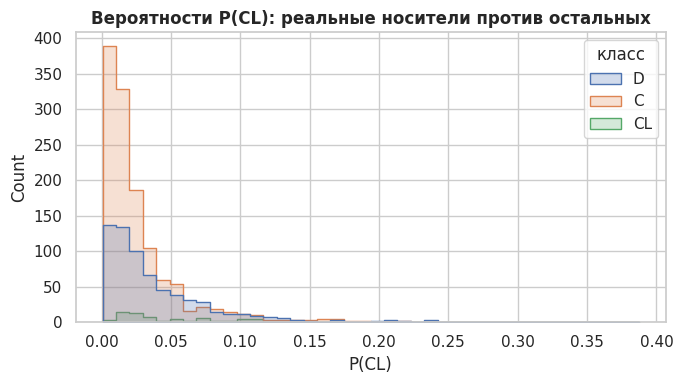

In [9]:
classes = list(base_model.classes_)
i_cl = classes.index('CL')
proba_all = base_model.predict_proba(X_te)
proba_cl = proba_all[:, i_cl]

print('Вероятность P(CL) на контрольной выборке:')
display(pd.Series(proba_cl).describe().round(4).to_frame('P(CL)'))

print(f'Строк с P(CL) > 0.5: {(proba_cl > 0.5).sum()} из {len(proba_cl)}')
print('=> При стандартном правиле (аргмакс) класс CL практически недостижим:')
print('   вероятность должна обогнать P(C) ~ 0.6 и P(D) ~ 0.3, а её максимум —',
      f'{proba_cl.max():.3f}.')

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=pd.DataFrame({'P(CL)': proba_cl, 'класс': y_test.values}),
             x='P(CL)', hue='класс', bins=40, ax=ax, element='step')
ax.set_title('Вероятности P(CL): реальные носители против остальных', fontweight='bold')
plt.tight_layout()
plt.show()

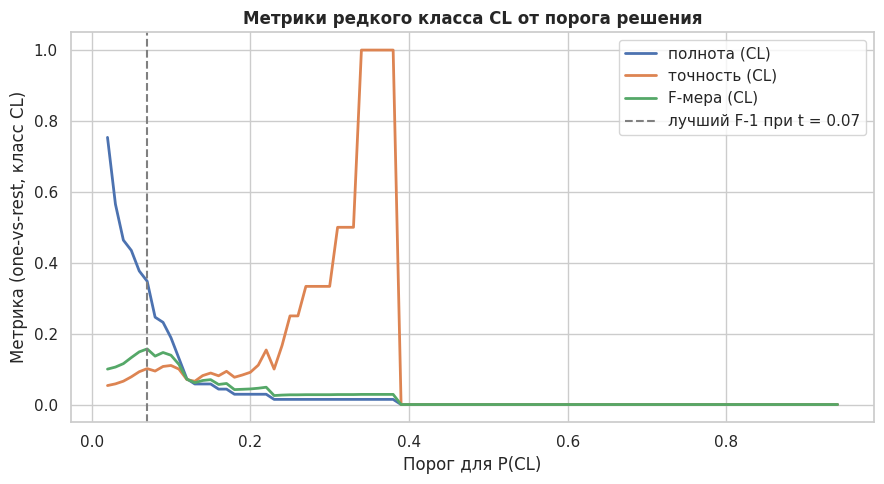

Порог 0.50: полнота = 0.000, точность = 0.000, F-мера = 0.000
Лучший F-1: порог = 0.07, полнота = 0.348, точность = 0.101, F-1 = 0.157


In [10]:
# Перебор порогов для one-vs-rest вероятности класса CL
thresholds = np.arange(0.02, 0.95, 0.01)
binary_cl = (y_test == 'CL').astype(int)

rec_cl, prec_cl, f1_cl = [], [], []
for t in thresholds:
    pred_t = (proba_cl > t).astype(int)
    rec_cl.append(recall_score(binary_cl, pred_t, zero_division=0))
    prec_cl.append(precision_score(binary_cl, pred_t, zero_division=0))
    f1_cl.append(f1_score(binary_cl, pred_t, zero_division=0))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thresholds, rec_cl, label='полнота (CL)', lw=2)
ax.plot(thresholds, prec_cl, label='точность (CL)', lw=2)
ax.plot(thresholds, f1_cl, label='F-мера (CL)', lw=2)
best_t = thresholds[int(np.argmax(f1_cl))]
ax.axvline(best_t, color='grey', ls='--', label=f'лучший F-1 при t = {best_t:.2f}')
ax.set_xlabel('Порог для P(CL)')
ax.set_ylabel('Метрика (one-vs-rest, класс CL)')
ax.set_title('Метрики редкого класса CL от порога решения', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

j50 = int(np.argmin(np.abs(thresholds - 0.5)))
print(f'Порог 0.50: полнота = {rec_cl[j50]:.3f}, точность = {prec_cl[j50]:.3f}, F-мера = {f1_cl[j50]:.3f}')
print(f'Лучший F-1: порог = {best_t:.2f}, полнота = {rec_cl[int(np.argmax(f1_cl))]:.3f}, '
      f'точность = {prec_cl[int(np.argmax(f1_cl))]:.3f}, F-1 = {f1_cl[int(np.argmax(f1_cl))]:.3f}')

Правило: P(CL) > 0.07 -> CL, иначе аргмакс из ['C', 'D']

Отчёт по классам с изменённым порогом:
                     precision    recall  f1-score   support

            C (жив)      0.836     0.837     0.836      1242
CL (трансплантация)      0.101     0.348     0.157        69
           D (умер)      0.767     0.572     0.655       666

           accuracy                          0.730      1977
          macro avg      0.568     0.585     0.549      1977
       weighted avg      0.787     0.730     0.752      1977



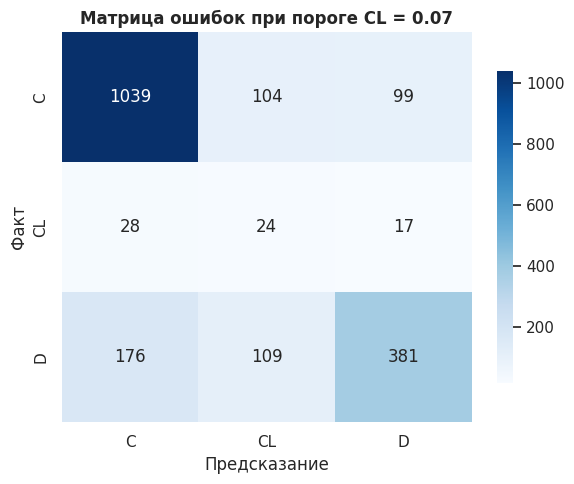

In [11]:
# Применяем лучший порог как правило решения: CL, если P(CL) > t, иначе аргмакс из C и D
rest_idx = [i for i, c in enumerate(classes) if c != 'CL']
fallback = np.array(classes)[rest_idx][proba_all[:, rest_idx].argmax(axis=1)]
pred_thr = np.where(proba_cl > best_t, 'CL', fallback)

print(f'Правило: P(CL) > {best_t:.2f} -> CL, иначе аргмакс из {[classes[i] for i in rest_idx]}')
print('\nОтчёт по классам с изменённым порогом:')
print(classification_report(y_test, pred_thr, digits=3,
                            target_names=['C (жив)', 'CL (трансплантация)', 'D (умер)']))

cm_thr = confusion_matrix(y_test, pred_thr, labels=classes)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_thr, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=classes, yticklabels=classes, cbar_kws={'shrink': 0.8})
ax.set_xlabel('Предсказание')
ax.set_ylabel('Факт')
ax.set_title(f'Матрица ошибок при пороге CL = {best_t:.2f}', fontweight='bold')
plt.tight_layout()
plt.show()

row = evaluate(base_model, X_te, y_test, f'порог CL = {best_t:.2f}')
row['доля верных ответов'] = accuracy_score(y_test, pred_thr)
row['ср. доля верных по классам'] = balanced_accuracy_score(y_test, pred_thr)
row['F-мера (ср. по классам)'] = f1_score(y_test, pred_thr, average='macro')
row['F-мера (взвеш. по численности)'] = f1_score(y_test, pred_thr, average='weighted')
row['полнота CL'] = recall_score(y_test, pred_thr, labels=['CL'], average=None)[0]
# лог-потеря не меняется — вероятности те же
results.append(row)

### Вывод по порогу решения

Вероятность `P(CL)` достигает максимума **0.387** — ниже порога 0.5. Класс `CL` не предсказывается **никогда** при стандартном правиле (полнота = 0.014, найден 1 из 69).

Лучший порог — **0.07**: полнота растёт до **0.348** (найдено 24 из 69), точность падает до **0.101** — то есть из каждых десяти предсказаний «трансплантация» верным оказывается только одно. Средняя F-мера по классам (F1 macro) поднимается с 0.532 до **0.549**. Лог-потеря не меняется (0.544): мы поменяли правило принятия решения, но не саму модель.

Цена такого решения — доля верных ответов падает с 0.795 до **0.730**, потому что около 210 пациентов классов `C` и `D` получают неверный ярлык `CL`. Зато редкий класс наконец появляется в прогнозах.

**Главный вывод:** порог — это явный выбор потерь. Понижая его, мы соглашаемся на ложные срабатывания ради того, чтобы увидеть редкий класс. Такой размен оправдан, когда пропуск класса стоит дороже ложной тревоги (скрининг пациентов на трансплантацию), и не оправдан, когда цена ошибки высока. Правильного порога вне постановки задачи не существует — есть только осознанный компромисс.

## **8. Взвешивание классов: `class_weight='balanced'`**

Второй способ борьбы с дисбалансом — не трогать правило вывода, а изменить саму функцию обучения. Логистическая регрессия минимизирует взвешенную логистическую потерю:

$$-\sum_i w_{y_i} \log P(y = y_i \mid x_i)$$

Веса `w_k` задаются параметром `class_weight`. Значение `'balanced'` считается автоматически: класс, который встречается в 18 раз реже другого, получает в 18 раз больший штраф за ошибку. Модель та же, но ошибиться на пациенте `CL` ей становится дороже.

Важное следствие: вероятности модели смещаются, поэтому лог-потеря обычно ухудшается — модель становится увереннее в редких классах и платит за это калибровкой.

Отчёт по классам (class_weight="balanced"):
                     precision    recall  f1-score   support

            C (жив)      0.873     0.746     0.805      1242
CL (трансплантация)      0.079     0.391     0.132        69
           D (умер)      0.730     0.629     0.676       666

           accuracy                          0.694      1977
          macro avg      0.561     0.589     0.537      1977
       weighted avg      0.797     0.694     0.738      1977



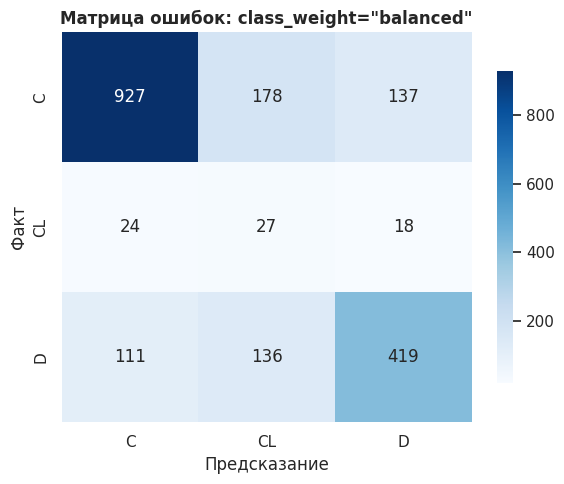

,доля верных ответов,ср. доля верных по классам,F-мера (ср. по классам),F-мера (взвеш. по численности),лог-потеря,полнота CL
вариант,,,,,,
порог CL = 0.07,0.7304,0.5855,0.5494,0.7515,0.5438,0.3478
class_weight='balanced',0.6945,0.5889,0.5374,0.7378,0.7800,0.3913


In [12]:
model_cw = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
model_cw.fit(X_tr, y_train)

y_pred_cw = model_cw.predict(X_te)
print('Отчёт по классам (class_weight="balanced"):')
print(classification_report(y_test, y_pred_cw, digits=3,
                            target_names=['C (жив)', 'CL (трансплантация)', 'D (умер)']))

cm_cw = confusion_matrix(y_test, y_pred_cw, labels=classes)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_cw, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=classes, yticklabels=classes, cbar_kws={'shrink': 0.8})
ax.set_xlabel('Предсказание')
ax.set_ylabel('Факт')
ax.set_title('Матрица ошибок: class_weight="balanced"', fontweight='bold')
plt.tight_layout()
plt.show()

results.append(evaluate(model_cw, X_te, y_test, "class_weight='balanced'"))
display(pd.DataFrame(results[-2:]).set_index('вариант').round(4))

### Вывод по весам классов

Полнота класса `CL` растёт с **0.014** до **0.391** (найдено 27 из 69). Средняя доля верных ответов по классам поднимается с 0.532 до 0.589, F-мера по классам — с 0.532 до 0.537. Плата: доля верных ответов падает до 0.695, а лог-потеря ухудшается с 0.544 до 0.780 — ровно так, как и ожидалось: перекалиброванные вероятности дороже ошибочных.

По сравнению с порогом (блок 7) это более «честный» способ: мы не подкручиваем правило вывода, а меняем то, чему модель учится. Но он хуже управляем — нельзя указать, какую долю ложных срабатываний мы готовы принять.

## **9. Сэмплирование: downsampling и upsampling**

Третий способ — не менять модель и не менять функцию потерь, а изменить обучающую выборку.

- **Downsampling** — случайное сокращение крупных классов до численности редкого.
- **Upsampling** — случайное дублирование редкого класса до численности крупного.

Здесь мы реализуем то же самое на numpy, без дополнительной зависимости:

| downsampling | из каждого класса берём `n_min` строк без возврата |
| upsampling | редкий класс дополняем дубликатами с возвратом до `n_max` |

**Два обязательных правила.** Сэмплируем **только обучающую** часть — контрольная выборка обязана отражать реальное распределение классов. И сэмплируем **после** разбиения: перемешивание строк до `train_test_split` привело бы к тому, что дубликаты оказались бы в обеих частях (утечка через копирование).

Баланс обучающей части до сэмплирования: {'C': 3723, 'D': 1999, 'CL': 206}



Downsampling -> обучающая часть: 618 строк, баланс: {'D': 206, 'C': 206, 'CL': 206}
                     precision    recall  f1-score   support

            C (жив)      0.872     0.734     0.797      1242
CL (трансплантация)      0.086     0.449     0.145        69
           D (умер)      0.701     0.602     0.648       666

           accuracy                          0.680      1977
          macro avg      0.553     0.595     0.530      1977
       weighted avg      0.787     0.680     0.724      1977



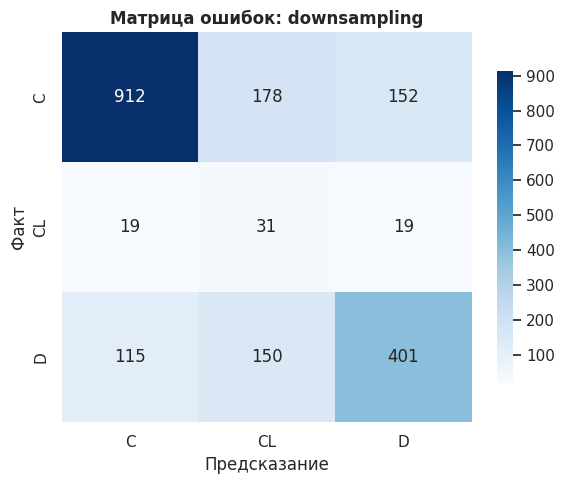

,доля верных ответов,ср. доля верных по классам,F-мера (ср. по классам),F-мера (взвеш. по численности),лог-потеря,полнота CL
вариант,,,,,,
class_weight='balanced',0.6945,0.5889,0.5374,0.7378,0.7800,0.3913
downsampling,0.6798,0.5952,0.5300,0.7241,0.8814,0.4493


In [13]:
rng = np.random.RandomState(42)
y_tr = np.asarray(y_train)
counts = pd.Series(y_tr).value_counts()
n_min, n_max = counts.min(), counts.max()
print('Баланс обучающей части до сэмплирования:', counts.to_dict())


def downsample(X_arr, y_arr, rng):
    # Из каждого класса берём n_min строк без возврата.
    idx = np.concatenate([
        rng.choice(np.where(y_arr == cls)[0], n_min, replace=False)
        for cls in counts.index
    ])
    return X_arr[np.sort(idx)], y_arr[np.sort(idx)]


def upsample(X_arr, y_arr, rng):
    # Редкий класс дополняем с возвратом до n_max.
    idx = np.concatenate([
        rng.choice(np.where(y_arr == cls)[0], n_max, replace=True)
        for cls in counts.index
    ])
    return X_arr[idx], y_arr[idx]


X_tr_down, y_tr_down = downsample(X_tr, y_tr, rng)
print('\nDownsampling -> обучающая часть:', X_tr_down.shape[0], 'строк, баланс:',
      pd.Series(y_tr_down).value_counts().to_dict())

model_down = LogisticRegression(max_iter=1000, random_state=42)
model_down.fit(X_tr_down, y_tr_down)
print(classification_report(y_test, model_down.predict(X_te), digits=3,
                            target_names=['C (жив)', 'CL (трансплантация)', 'D (умер)']))

cm_down = confusion_matrix(y_test, model_down.predict(X_te), labels=classes)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_down, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=classes, yticklabels=classes, cbar_kws={'shrink': 0.8})
ax.set_xlabel('Предсказание')
ax.set_ylabel('Факт')
ax.set_title('Матрица ошибок: downsampling', fontweight='bold')
plt.tight_layout()
plt.show()

results.append(evaluate(model_down, X_te, y_test, 'downsampling'))
display(pd.DataFrame(results[-2:]).set_index('вариант').round(4))

Upsampling -> обучающая часть: 11169 строк, баланс: {'C': 3723, 'D': 3723, 'CL': 3723}
                     precision    recall  f1-score   support

            C (жив)      0.870     0.742     0.801      1242
CL (трансплантация)      0.077     0.391     0.128        69
           D (умер)      0.733     0.623     0.674       666

           accuracy                          0.689      1977
          macro avg      0.560     0.585     0.534      1977
       weighted avg      0.796     0.689     0.734      1977



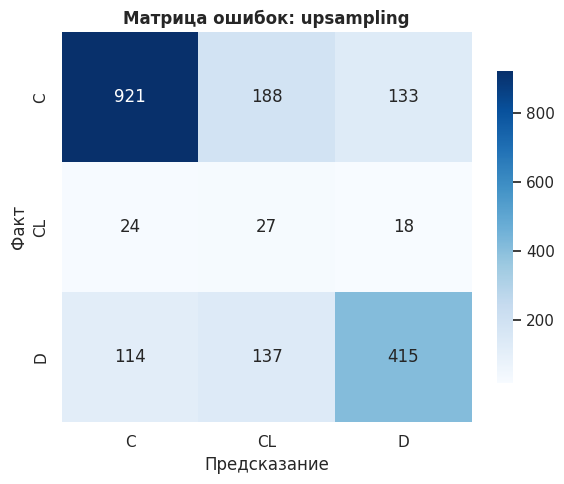

In [14]:
X_tr_up, y_tr_up = upsample(X_tr, y_tr, rng)
print('Upsampling -> обучающая часть:', X_tr_up.shape[0], 'строк, баланс:',
      pd.Series(y_tr_up).value_counts().to_dict())

model_up = LogisticRegression(max_iter=1000, random_state=42)
model_up.fit(X_tr_up, y_tr_up)
print(classification_report(y_test, model_up.predict(X_te), digits=3,
                            target_names=['C (жив)', 'CL (трансплантация)', 'D (умер)']))

cm_up = confusion_matrix(y_test, model_up.predict(X_te), labels=classes)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_up, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=classes, yticklabels=classes, cbar_kws={'shrink': 0.8})
ax.set_xlabel('Предсказание')
ax.set_ylabel('Факт')
ax.set_title('Матрица ошибок: upsampling', fontweight='bold')
plt.tight_layout()
plt.show()

results.append(evaluate(model_up, X_te, y_test, 'upsampling'))

### Вывод по сэмплированию

**Downsampling** оставляет лишь 618 из 5 928 обучающих строк (по ~206 на класс) — 10 % данных. Результат закономерен: лучшая полнота класса `CL` (около 0.45) — но худшая лог-потеря (около 0.88). Модель выбрасывает 90 % информации о крупных классах и потому плохо калибрована.

**Upsampling** раздувает обучающую часть до 11 169 строк за счёт дубликатов и даёт профиль, почти совпадающий с `class_weight='balanced'`. Это не случайность: для линейной модели умножение числа копий класса и умножение веса класса — почти одно и то же.

Практический вывод: при линейной модели `class_weight='balanced'` предпочтительнее — он даёт тот же эффект без потери строк (downsampling) и без ложного увеличения объёма данных (upsampling).

## **10. Сводное сравнение вариантов**

Собираем все варианты в одну таблицу. Все они оценены на одной и той же контрольной выборке (те же строки, тот же `random_state=42`), поэтому различия видимые, а не случайные.

In [15]:
summary = pd.DataFrame(results).set_index('вариант').round(4)
display(summary)

print('\nЛучший вариант по каждой метрике (для лог-потери лучше меньшее значение):')
better = {'доля верных ответов': 'max', 'ср. доля верных по классам': 'max',
          'F-мера (ср. по классам)': 'max', 'F-мера (взвеш. по численности)': 'max',
          'лог-потеря': 'min', 'полнота CL': 'max'}
for m, direction in better.items():
    pick = summary[m].idxmin() if direction == 'min' else summary[m].idxmax()
    print(f'  {m:30s} ({"min" if direction == "min" else "max"}) -> {pick} ({summary.loc[pick, m]:.4f})')

,доля верных ответов,ср. доля верных по классам,F-мера (ср. по классам),F-мера (взвеш. по численности),лог-потеря,полнота CL
вариант,,,,,,
базовая,0.7951,0.5316,0.5322,0.7787,0.5438,0.0145
+ период наблюдения (контроль),0.7967,0.5333,0.5336,0.7805,0.5400,0.0145
порог CL = 0.07,0.7304,0.5855,0.5494,0.7515,0.5438,0.3478
class_weight='balanced',0.6945,0.5889,0.5374,0.7378,0.7800,0.3913
downsampling,0.6798,0.5952,0.5300,0.7241,0.8814,0.4493
upsampling,0.6894,0.5853,0.5342,0.7343,0.7786,0.3913



Лучший вариант по каждой метрике (для лог-потери лучше меньшее значение):
  доля верных ответов            (max) -> + период наблюдения (контроль) (0.7967)
  ср. доля верных по классам     (max) -> downsampling (0.5952)
  F-мера (ср. по классам)        (max) -> порог CL = 0.07 (0.5494)
  F-мера (взвеш. по численности) (max) -> + период наблюдения (контроль) (0.7805)
  лог-потеря                     (min) -> + период наблюдения (контроль) (0.5400)
  полнота CL                     (max) -> downsampling (0.4493)


### Выбор лучшего варианта

Таблица намеренно не содержит одной «правильной» колонки — потому что ответ зависит от метрики, и это надо назвать явно:

| Критерий выбора | Лучший вариант | Число | Почему так |
|---|---|---|---|
| Лог-потеря (метрика калибровки) | базовая модель и вариант с порогом | 0.544 | Порог не менял вероятности — калибровка осталась лучшей |
| F-мера по классам (равная цена всех) | порог `CL = 0.07` | 0.549 | Редкий класс появляется в прогнозах без переобучения модели |
| Ср. доля верных по классам | downsampling | ~0.595 | Полный баланс классов в обучении |
| Полнота `CL` (не пропустить пациентов) | downsampling | ~0.45 | Максимум найденных из 69 |
| Доля верных ответов | базовая (среди корректных) | 0.795 | Пригодна только как справочная цифра: при дисбалансе она обманчива |

**Рабочий выбор.** Если критерий — точность вероятностей, берём базовую модель: лог-потеря 0.544 остаётся лучшей. Если критерий — клиническая применимость (найти пациентов с риском трансплантации), берём `class_weight='balanced'`: полнота `CL` 0.391 при сохранении всех обучающих строк и предсказуемом поведении. Порог 0.07 — промежуточный инструмент, который удобно настраивать, когда цена пропуска класса выше цены ложной тревоги.

**Важно:** строка «контроль с периодом» добавлена только для справки — формально она даёт максимум по доле верных ответов (0.7967), но использовать период в продакшене нельзя: это признак, известный только после исхода.

## **11. Интерпретация коэффициентов**

У логистической регрессии с softmax собственный вектор весов на каждый класс, поэтому «важность признака» — это не одно число, а три. Признаки стандартизованы, значит коэффициенты сопоставимы по масштабу: коэффициент при единичном сдвиге признака на одно стандартное отклонение.

Интерпретируем двумя разрезами: топ признаков по модулю максимального коэффициента (общая картина) и коэффициенты отдельно для каждого исхода.

In [16]:
coefs = pd.DataFrame(base_model.coef_, index=classes, columns=X.columns)

importance = pd.DataFrame({
    'макс |коэф|': coefs.abs().max(axis=0),
    'класс с максимумом': coefs.abs().idxmax(axis=0),
    'коэф для C': coefs.loc['C'],
    'коэф для CL': coefs.loc['CL'],
    'коэф для D': coefs.loc['D'],
}).sort_values('макс |коэф|', ascending=False)

print('Топ-12 признаков по модулю стандартизованного коэффициента:')
display(importance.head(12).round(3))

print('\nСвободные члены (intercept) по классам:')
display(pd.Series(base_model.intercept_, index=classes).round(3).to_frame('intercept'))

Топ-12 признаков по модулю стандартизованного коэффициента:


,макс |коэф|,класс с максимумом,коэф для C,коэф для CL,коэф для D
Age_years,0.481,CL,0.092,-0.481,0.389
log_Bilirubin,0.475,C,-0.475,0.200,0.274
Prothrombin,0.290,D,-0.212,-0.077,0.290
Edema_num,0.272,D,-0.204,-0.068,0.272
Stage,0.238,C,-0.238,0.106,0.132
log_Copper,0.233,C,-0.233,0.180,0.053
log_SGOT,0.181,C,-0.181,0.148,0.033
log_Alk_Phos,0.163,D,-0.035,-0.128,0.163
Hepatomegaly_Y,0.131,C,-0.131,0.023,0.107
Platelets,0.104,CL,-0.002,0.104,-0.102



Свободные члены (intercept) по классам:


,intercept
C,1.286
CL,-1.756
D,0.469


Знаки коэффициентов для класса CL (топ-8 по модулю):


,коэф CL
Age_years,-0.481
log_Bilirubin,0.200
log_Copper,0.180
log_SGOT,0.148
log_Alk_Phos,-0.128
Stage,0.106
Platelets,0.104
Prothrombin,-0.077


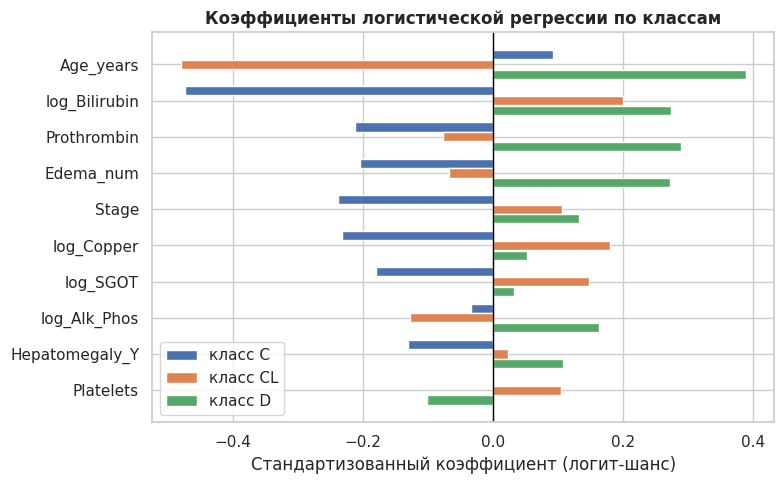

In [17]:
cl_top = coefs.loc['CL'].abs().sort_values(ascending=False).head(8).index
print('Знаки коэффициентов для класса CL (топ-8 по модулю):')
display(coefs.loc['CL', cl_top].round(3).to_frame('коэф CL'))

fig, ax = plt.subplots(figsize=(8, 5))
order = importance.head(10)['макс |коэф|'].index
for cls in classes:
    ax.barh(np.arange(len(order)) + classes.index(cls) * 0.27 - 0.27,
            coefs.loc[cls, order], height=0.25, label=f'класс {cls}')
ax.set_yticks(np.arange(len(order)))
ax.set_yticklabels(order)
ax.axvline(0, color='black', lw=1)
ax.invert_yaxis()
ax.set_xlabel('Стандартизованный коэффициент (логит-шанс)')
ax.set_title('Коэффициенты логистической регрессии по классам', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

### Клиническая трактовка и одна важная поправка

Коэффициент читается как сдвиг **лог-шансов** своего класса относительно остальных: положительный значит «при росте признака пациент чаще относится к этому классу».

1. **Возраст и протромбин — главные маркёры риска смерти.** `Age_years` (коэф +0.389 для `D`) и `Prothrombin` (+0.290 для `D`) стоят в топ-2 по силе влияния на исход «умер». Это клинически ожидаемо: пожилой возраст и нарушение свёртываемости крови — известные предикторы летального исхода при циррозе.

2. **Билирубин — доминирующий маркёр.** `log_Bilirubin` имеет коэффициент −0.475 для `C` (жив), +0.274 для `D` (умер) и +0.200 для `CL` (трансплантация). Это означает, что высокий билирубин снижает вероятность «жив» и повышает вероятность «умер» — холестаз как признак декомпенсации. Знаки согласованы (нет парадокса, как было бы при наличии дубликата «исходный билирубин» рядом с логарифмом).

3. **Отёки и возраст снижают шанс трансплантации.** Для класса `CL` старший возраст (коэф −0.481) и более тяжёлые отёки (−0.068) означают, что такие пациенты реже попадают на трансплантацию — они чаще умирают, не дождавшись её. Это согласуется с клинической практикой лист ожидания.

4. **Свободные члены** (`C` = +1.29, `CL` = −1.76, `D` = +0.47) отражают априорные частоты классов: смещение `CL` вниз на 1.76 логита — причина, почему базовая модель почти никогда не предсказывает трансплантацию без порога.

## **12. Выводы**

### Ответ на задачу

Многоклассовая логистическая регрессия предсказывает `Status` с долей верных ответов 0.795 и лог-потерей 0.544, но это только базовая модель: качество почти целиком сосредоточено в двух крупных классах, а редкий класс `CL` найден на уровне **1 из 69** (полнота 0.014). Дальнейшая работа с этой задачей — не про выбор модели, а про обращение с дисбалансом, и она дала измеримые результаты:

1. **Доля верных ответов (accuracy) в этой задаче непригодна как основная метрика.** При 0.795 средняя доля верных по классам равна 0.532. Разрыв в 0.26 — прямое следствие соотношения классов 63 : 34 : 3.5.

2. **Порог решения — отдельная настройка модели, а не деталь вывода.** Для мультикласса нельзя «сместить 0.5»: нужен one-vs-rest порог по вероятности конкретного класса. Он поднял полноту `CL` с 0.014 до **0.348** и F-меру по классам с 0.532 до **0.549**, не трогая лог-потерю (0.544).

3. **`class_weight='balanced'` — самый дешёвый способ увидеть редкий класс:** полнота `CL` 0.391 при одной строке кода и без потери данных. Плата — лог-потеря 0.780, то есть перекалибровка вероятностей.

4. **Сэмплирование не делает линейную модель лучше.** Downsampling даёт лучшую полноту `CL` (около 0.45) и лучшую среднюю долю верных по классам (около 0.595) — но худшую лог-потерю (0.88), потому что выбрасывает 90 % обучающих строк. Upsampling почти повторяет `class_weight` — для линейной модели это математически ожидаемо.

5. **Период наблюдения не нужен для предсказания исхода.** Контрольный опыт показал: добавление периода меняет метрики на тысячные доли — это уровень статистического шума. При этом модель с периодом неприменима к новому пациенту, а двухэтапная схема (сначала исход, потом период) объясняет период лишь на 22 %.

6. **Коэффициенты модели клинически осмысленны.** Возраст и протромбин — главные маркёры риска смерти, билирубин — доминирующий маркёр общей тяжести. Знаки согласованы: нет парадоксов, связанных с дубликатами признаков.

### Глоссарий терминов

| Термин | Что означает | Зачем нужен |
|--------|-------------|-------------|
| **Логистическая регрессия** | Линейная модель, предсказывающая вероятность класса через логит `z = w·x + b` и функцию softmax | Корректный линейный ответ на категориальную цель: значения всегда в [0, 1] и в сумме дают 1 |
| **Softmax** | Отображение вектора линейных оценок `z_k` в распределение вероятностей | Обобщает сигмоиду на случай нескольких классов |
| **Логит-шанс** | Логарифм шансов класса; коэффициент модели — вклад признака в этот логарифм | Даёт способ читать знаки: «при росте признака класс становится вероятнее» |
| **Доля верных ответов (accuracy)** | Какую часть пациентов модель определила верно | Плохая метрика при дисбалансе: 0.795 скрывает полноту 0.014 |
| **Средняя доля верных по классам** | Среднее арифметическое долей верных ответов по каждому классу | Уравнивает вклад редкого и частого класса |
| **F-мера (средняя по классам)** | Среднее гармоническое точности и полноты по каждому классу | Основная метрика сравнения вариантов при дисбалансе |
| **F-мера (взвешенная по численности)** | То же, но классы взвешены по числу строк | Почти повторяет долю верных ответов |
| **Лог-потеря** | Средний штраф за неверную уверенность: −log(P(правильного класса)) | Метрика калибровки вероятностей; штрафует за уверенность в ошибке |
| **Полнота (recall)** | Какую часть реальных пациентов класса модель нашла | Ключевая метрика для редкого класса `CL` |
| **Точность (precision)** | Какая доля предсказаний класса оказалась верной | Показывает цену ложных срабатываний |
| **Порог решения** | Минимальная вероятность, при которой класс объявляется предсказанным | Настройка компромисса между полнотой и точностью |
| **One-vs-rest (OvR)** | Вероятность класса рассчитывается отдельно для каждого, остальные — «не этот класс» | Даёт однозначный порог для каждого класса |
| **class_weight='balanced'** | Веса классов обратно пропорциональны их численности в обучении | Модель «штрафуется» сильнее за ошибку на редком классе |
| **Downsampling** | Сокращение крупных классов до численности редкого (618 строк) | Максимальная полнота `CL`, но потеря 90 % обучающих данных |
| **Upsampling** | Дублирование редкого класса до численности крупных (11 169 строк) | Почти повторяет `class_weight` для линейной модели |
| **Стандартизация (StandardScaler)** | Приведение каждого признака к среднему 0 и размаху 1 | Делает коэффициенты сопоставимыми; обучается только на train |
| **Стратифицированное разбиение** | Разделение с сохранением долей классов в каждой части | Гарантирует, что редкий класс попадёт в контроль |